In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from src.dataset import load_dataset

In [2]:
DATA_DIR = Path('../data/Audio_Files')
features, labels = load_dataset(DATA_DIR)
print(f'Features shape: {features.shape}')
print(f'Labels: {np.unique(labels, return_counts=True)}')

chroma_names = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']
mfcc_names = [f'MFCC_{i}' for i in range(13)]
feature_names = chroma_names + mfcc_names

df = pd.DataFrame(features, columns=feature_names)
df['label'] = labels
df.describe()

Features shape: (859, 25)
Labels: (array(['Major', 'Minor'], dtype='<U5'), array([502, 357]))


,C,C#,D,D#,E,F,F#,G,G#,A,...,MFCC_3,MFCC_4,MFCC_5,MFCC_6,MFCC_7,MFCC_8,MFCC_9,MFCC_10,MFCC_11,MFCC_12
count,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,...,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000
mean,0.323024,0.312717,0.273883,0.324327,0.333067,0.301869,0.317444,0.276462,0.252278,0.294716,...,-3.138778,4.750953,-2.786523,-12.382829,-13.070283,-12.047969,-10.335616,-6.828805,-8.719871,-9.822688
std,0.217492,0.233151,0.204756,0.211782,0.236306,0.217656,0.223056,0.196950,0.168910,0.222733,...,6.666857,6.266827,9.914323,11.634320,8.699584,7.654587,9.336998,9.112071,8.130005,9.076723
min,0.016098,0.008812,0.020264,0.015523,0.016378,0.009013,0.014467,0.017545,0.012466,0.015909,...,-28.034618,-17.227503,-40.395630,-49.467422,-41.067650,-41.053493,-41.337814,-41.797001,-39.774868,-38.027000
25%,0.160367,0.146346,0.131267,0.152378,0.151043,0.151676,0.148607,0.123790,0.129150,0.140049,...,-7.615556,0.848549,-9.147417,-20.973413,-18.329150,-16.303026,-16.352337,-12.043200,-13.708268,-14.979810
50%,0.260319,0.246939,0.203735,0.274797,0.253363,0.243440,0.251580,0.220876,0.219316,0.243166,...,-3.191723,4.412172,-0.378374,-9.785098,-11.370294,-11.265092,-9.232935,-5.361887,-6.650806,-8.320539
75%,0.445766,0.403780,0.358549,0.465949,0.492001,0.377854,0.458959,0.380666,0.338465,0.353647,...,1.455244,8.482818,4.568335,-2.801474,-6.743618,-6.993454,-3.363418,-0.376329,-3.164634,-3.792532
max,0.966439,0.977679,0.958157,0.983869,0.964987,0.967515,0.946671,0.956524,0.886134,0.958023,...,13.950696,28.999994,14.256806,7.772183,7.141176,9.965493,11.693661,14.564200,12.848412,15.329886


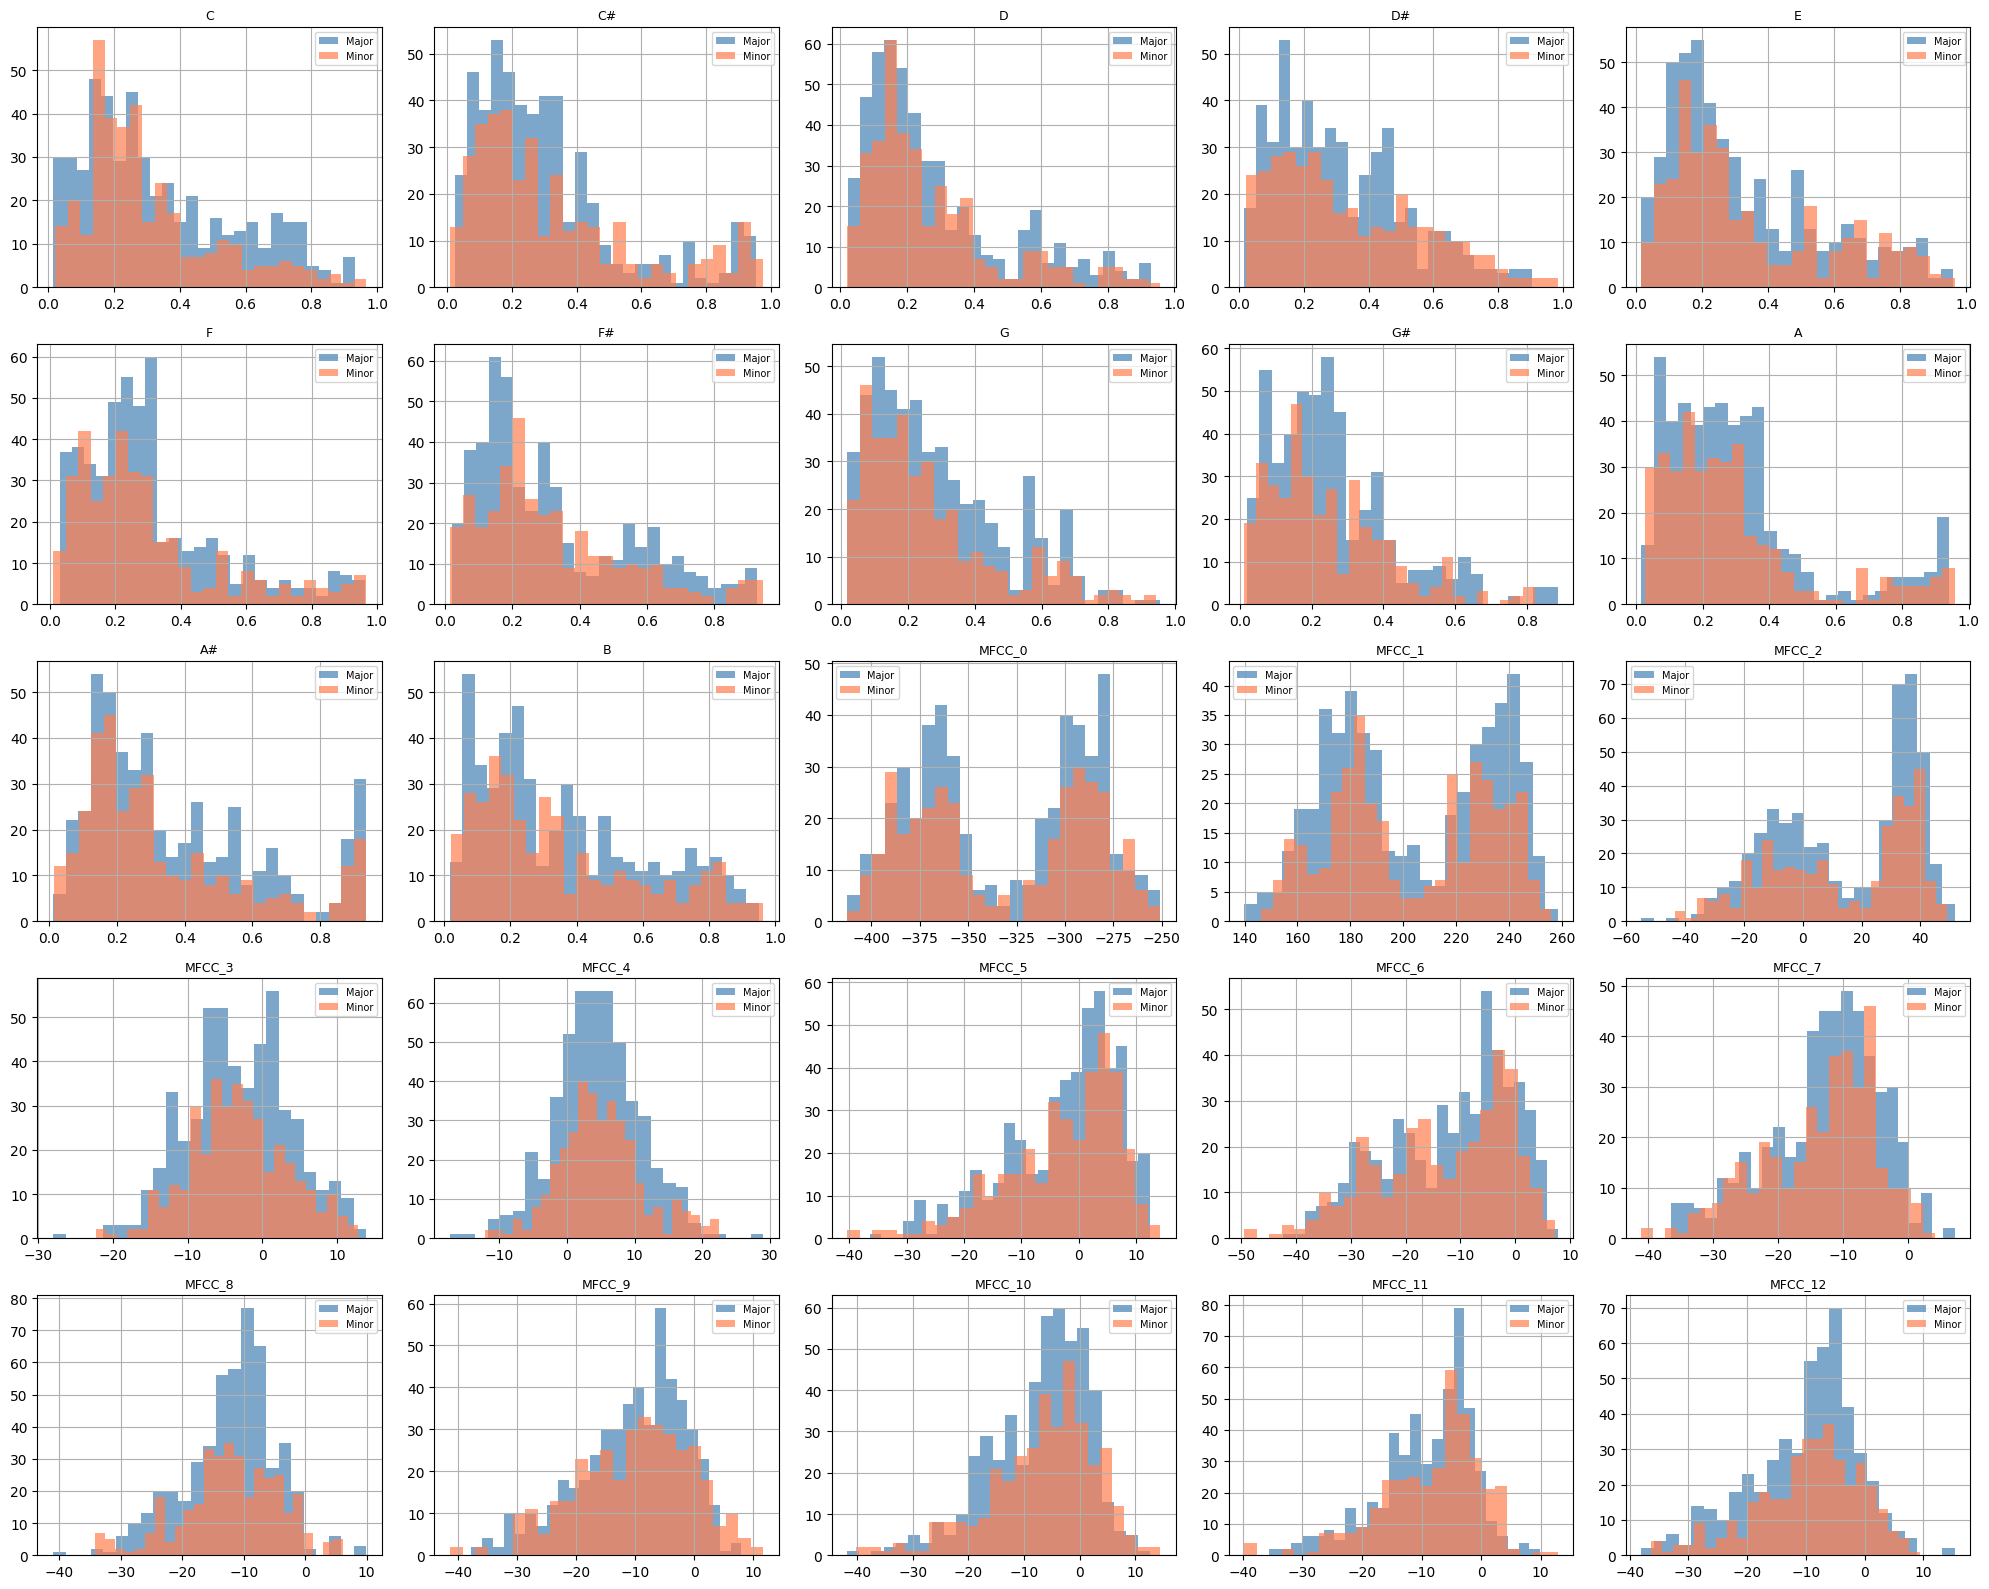

In [3]:
fig, axes = plt.subplots(5, 5, figsize=(20, 16))
axes = axes.flatten()
for i, col in enumerate(feature_names):
    ax = axes[i]
    df[df['label'] == 'Major'][col].hist(ax=ax, bins=25, alpha=0.7, color='steelblue', label='Major')
    df[df['label'] == 'Minor'][col].hist(ax=ax, bins=25, alpha=0.7, color='coral', label='Minor')
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

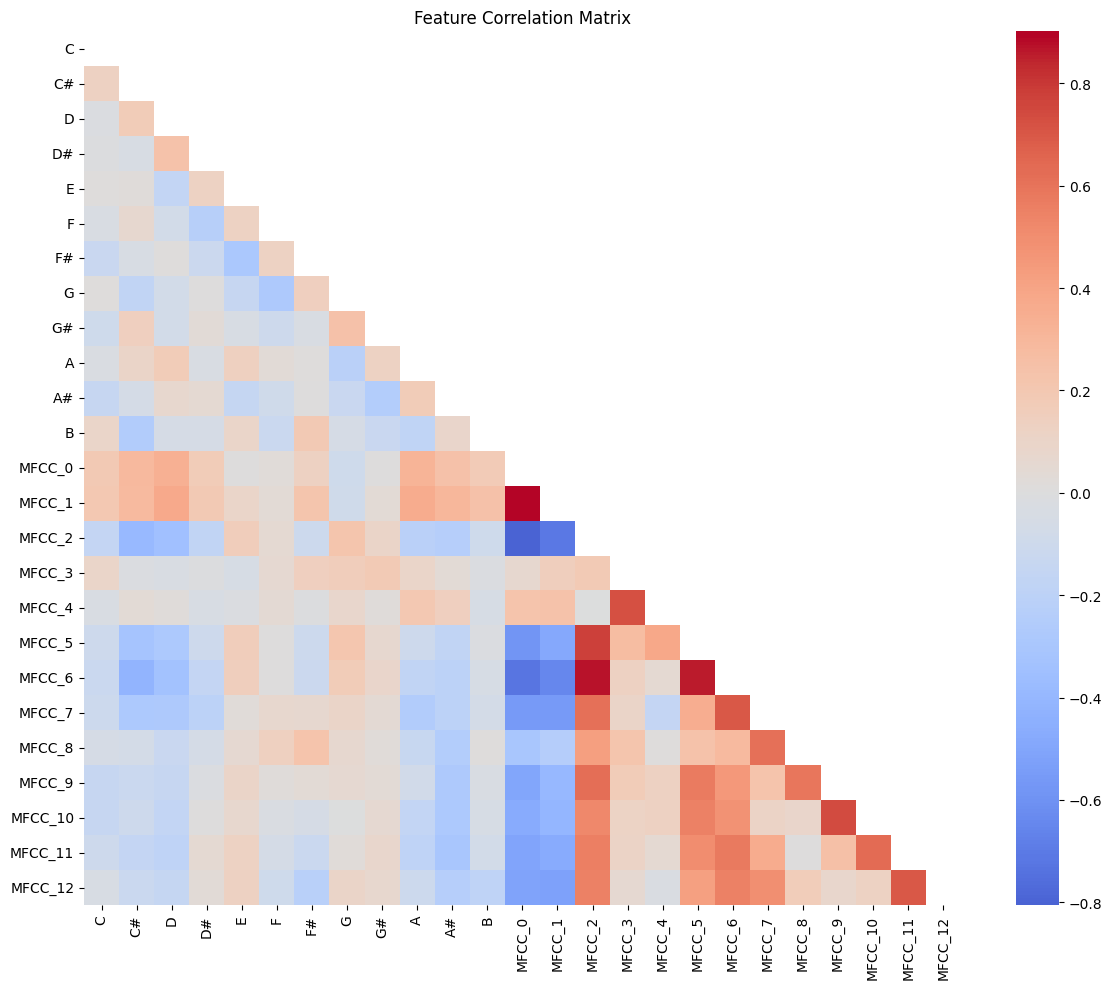

In [4]:
fig, ax = plt.subplots(figsize=(12, 10))
corr = df[feature_names].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=False,
            xticklabels=feature_names, yticklabels=feature_names, ax=ax)
ax.set_title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

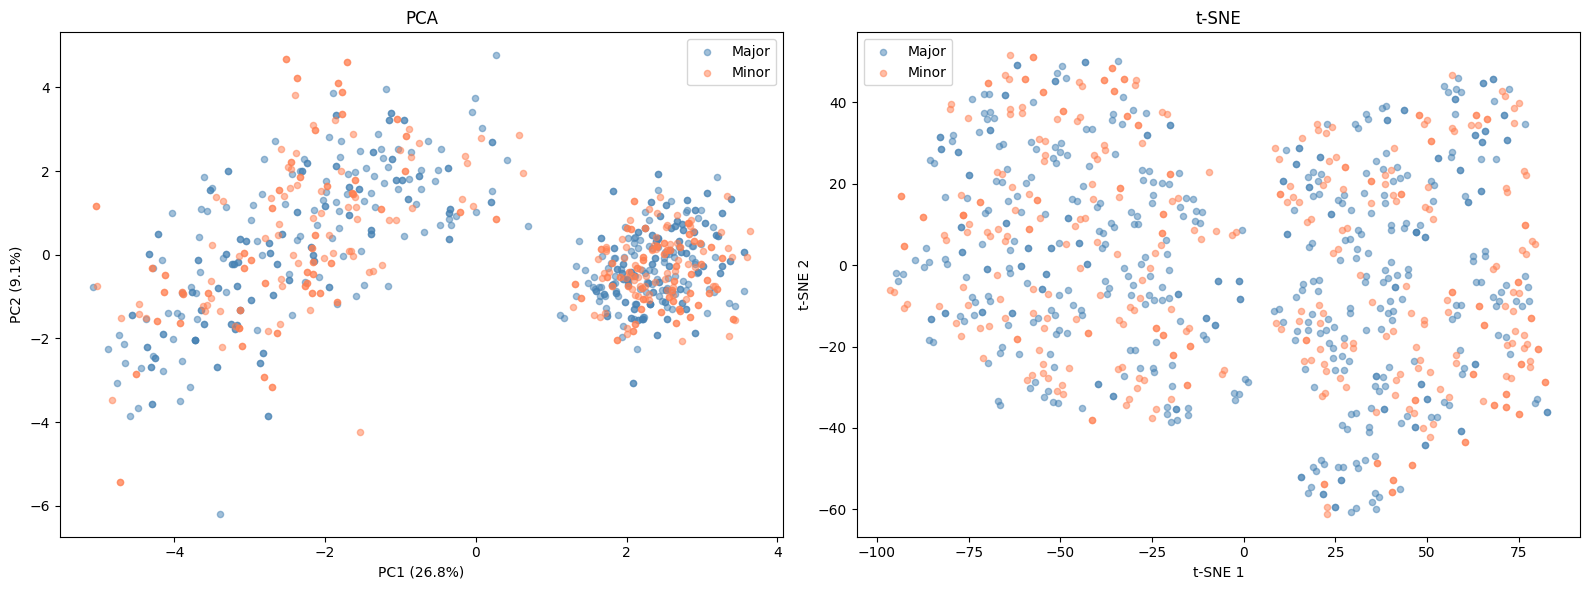

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
le = LabelEncoder()
y_encoded = le.fit_transform(labels)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for cls, color, name in [(0, 'steelblue', 'Major'), (1, 'coral', 'Minor')]:
    mask = y_encoded == cls
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=name, alpha=0.5, s=20)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PCA')
axes[0].legend()

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

for cls, color, name in [(0, 'steelblue', 'Major'), (1, 'coral', 'Minor')]:
    mask = y_encoded == cls
    axes[1].scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=color, label=name, alpha=0.5, s=20)
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].set_title('t-SNE')
axes[1].legend()

plt.tight_layout()
plt.show()

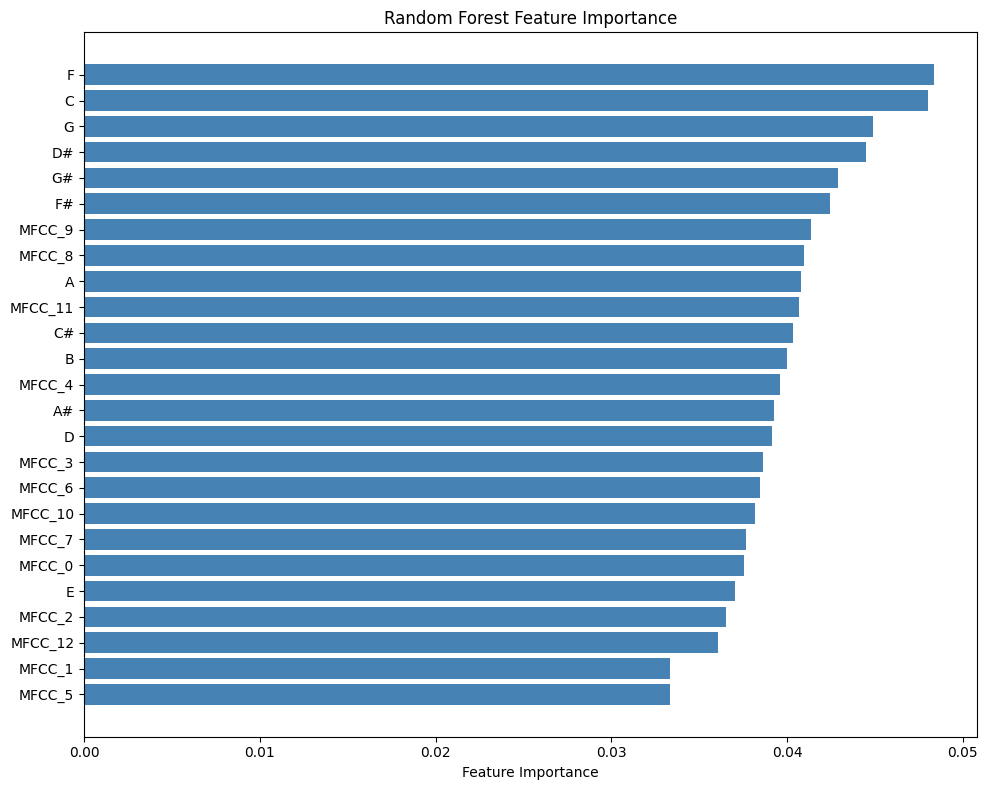

In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_scaled, y_encoded)

importances = rf.feature_importances_
sorted_idx = np.argsort(importances)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(np.array(feature_names)[sorted_idx], importances[sorted_idx], color='steelblue')
ax.set_xlabel('Feature Importance')
ax.set_title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()